## Random Forest Classifier

### Data Loading and Verify Train-Test Split

We load the feature-engineered German Credit dataset from the above  and use the predefined stratified 80/20 train-test split (random_state=42).

The training set is used for model fitting and hyperparameter tuning through cross-validation, while the test set is reserved exclusively for final model evaluation.

The target variable is `default`, and the `split` column is excluded from the predictors to prevent data leakage.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

DATA_PATH = 'data/processed/german_clean_modified.csv'
df = pd.read_csv(DATA_PATH)
assert {'default', 'split'}.issubset(df.columns)
assert set(df['split'].unique()) == {'train', 'test'}
assert df['default'].isin([0, 1]).all()
assert not df.isna().any().any(), 'Review missing values before fitting.'
rf_train_df = df.loc[df['split'].eq('train')].copy()
rf_test_df = df.loc[df['split'].eq('test')].copy()
rf_X_train = rf_train_df.drop(columns=['default', 'split'])
rf_X_test = rf_test_df.drop(columns=['default', 'split'])
rf_y_train = rf_train_df['default'].astype(int)
rf_y_test = rf_test_df['default'].astype(int)
assert rf_X_train.columns.equals(rf_X_test.columns)
print('Shape:', df.shape, '| Train:', rf_X_train.shape, '| Test:', rf_X_test.shape)
print('Default rates:', rf_y_train.mean(), rf_y_test.mean())
print('Feature types:', rf_X_train.dtypes.value_counts().to_dict())

Shape: (1000, 40) | Train: (800, 38) | Test: (200, 38)
Default rates: 0.3 0.3
Feature types: {dtype('O'): 18, dtype('int64'): 11, dtype('float64'): 9}


### Feature Sets and Model Design Rationale

Three Random Forest configurations are developed to evaluate the effects of hyperparameter tuning and feature reduction on credit default prediction. All models use the same stratified 80/20 train-test split established in Section 4 (`random_state=42`), with categorical variables transformed using one-hot encoding. Numerical variables are retained without scaling, as Random Forest models do not require feature standardization.

#### Baseline Model: Standard Random Forest

The baseline model follows the Random Forest implementation introduced in **Chapter 7 (Notebook 01)**, using 100 decision trees (`n_estimators=100`) with the remaining hyperparameters set to their scikit-learn defaults. All 38 predictors from feature engineering is retained, including original borrower characteristics and engineered features. After one-hot encoding, the model uses 98 input features.

**Purpose:** To establish a benchmark for evaluating whether hyperparameter tuning and feature reduction improve predictive performance.

#### Model 1: Hyperparameter-Tuned Random Forest (Full Features)

Model 1 retains the same 38 predictors as the baseline, allowing the effects of hyperparameter tuning to be examined without changing the feature set.

Hyperparameters are optimized using `RandomizedSearchCV` with 30 candidate configurations and stratified five-fold cross-validation (150 fits). ROC-AUC is used as the optimization metric because it measures the model's ability to distinguish defaulting from non-defaulting borrowers across classification thresholds.

The search considers the number of trees (`n_estimators`), maximum tree depth (`max_depth`), minimum samples required for splitting (`min_samples_split`), minimum samples per leaf (`min_samples_leaf`), number of features considered at each split (`max_features`), and class weighting (`class_weight`).

**Purpose:** To assess whether optimizing model complexity and class weighting improves predictive performance relative to the standard Random Forest.

#### Model 2: Hyperparameter-Tuned Random Forest (Reduced Features)

Model 2 investigates whether a simpler feature set can achieve comparable predictive performance while reducing redundancy and improving interpretability. The feature set is reduced from **38 to 21 predictors** using domain-based reasoning rather than test-set performance.

The following features are excluded:

- **Log transformations (`log_*`):** These contain overlapping information with the original numerical variables, such as `duration`, `credit_amount`, and `age`. Random Forest can capture non-linear relationships without requiring logarithmic transformations.
- **Duplicated categorical representations:** `emp_category`, `emp_years`, `purpose_grp`, `age_group`, and `amount_bin` are removed because their underlying information is already represented by the original employment

In [35]:
DROP_REDUCED = [c for c in rf_X_train.columns if c.startswith('log_')]
DROP_REDUCED += ['emp_category', 'emp_years', 'purpose_grp', 'age_group', 'amount_bin',
                 'monthly_payment', 'income_index', 'lti', 'total_dti', 'dti', 'other_installments']
DROP_REDUCED = sorted(set(DROP_REDUCED) & set(rf_X_train.columns))
FULL_FEATURES = rf_X_train.columns.tolist()
REDUCED_FEATURES = [c for c in FULL_FEATURES if c not in DROP_REDUCED]
assert REDUCED_FEATURES and len(REDUCED_FEATURES) < len(FULL_FEATURES)
print('Full:', len(FULL_FEATURES), 'Reduced:', len(REDUCED_FEATURES))
print('Removed:', DROP_REDUCED)
print('Retained:', REDUCED_FEATURES)

Full: 38 Reduced: 21
Removed: ['age_group', 'amount_bin', 'dti', 'emp_category', 'emp_years', 'income_index', 'log_age', 'log_credit_amount', 'log_duration', 'log_income_index', 'log_lti', 'log_monthly_payment', 'lti', 'monthly_payment', 'other_installments', 'purpose_grp', 'total_dti']
Retained: ['checking', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings', 'employment', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment', 'housing', 'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'sex']


### One-hot encoding, Shared Preprocessing and Cross-Validation

Random Forest requires numerical inputs. We therefore use one-hot encoding for categorical variables while retaining numerical features for all three models. 

Preprocessing is fitted only on the training set to prevent data leakage. The same fitted transformation is subsequently applied to the test set.

In [36]:
RANDOM_STATE = 42
RF_THRESHOLD = 1 / 6
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
PARAMS = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': [None, 'balanced']
}
def make_pipeline(features, n_estimators=100):
    subset = rf_X_train[features]
    categorical = subset.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    numeric = subset.select_dtypes(include='number').columns.tolist()
    transform = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('num', 'passthrough', numeric)
    ])
    return Pipeline([
        ('preprocessor', transform),
        ('classifier', RandomForestClassifier(n_estimators=n_estimators,
                                              random_state=RANDOM_STATE, n_jobs=1))
    ])

def tune_model(features):
    search = RandomizedSearchCV(make_pipeline(features), PARAMS, n_iter=30,
                                scoring='roc_auc', cv=CV, random_state=RANDOM_STATE,
                                n_jobs=-1, verbose=1, refit=True)
    search.fit(rf_X_train[features], rf_y_train)
    return search

# Show exactly what gets one-hot encoded in each feature set.
for label, features in [('Baseline / Model 1 (all)', FULL_FEATURES),
                        ('Model 2 (reduced)', REDUCED_FEATURES)]:
    cat_cols = rf_X_train[features].select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    num_cols = rf_X_train[features].select_dtypes(include='number').columns.tolist()
    print(f'\n{label}: {len(features)} raw predictors; {len(cat_cols)} categorical, {len(num_cols)} numeric')
    print('One-hot encoded categorical columns:', cat_cols)
    print('Passed-through numerical columns:', num_cols)



Baseline / Model 1 (all): 38 raw predictors; 18 categorical, 20 numeric
One-hot encoded categorical columns: ['checking', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker', 'sex', 'emp_category', 'purpose_grp', 'age_group', 'amount_bin']
Passed-through numerical columns: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'dependents', 'log_duration', 'log_credit_amount', 'log_age', 'monthly_payment', 'dti', 'income_index', 'lti', 'total_dti', 'other_installments', 'log_monthly_payment', 'log_income_index', 'log_lti', 'emp_years']

Model 2 (reduced): 21 raw predictors; 14 categorical, 7 numeric
One-hot encoded categorical columns: ['checking', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker', 's

### Fit baseline and tune both candidate feature sets (Training)

In [37]:
baseline = make_pipeline(FULL_FEATURES, n_estimators=100)
baseline_cv_auc = cross_val_score(baseline, rf_X_train[FULL_FEATURES], rf_y_train,
                                  cv=CV, scoring='roc_auc', n_jobs=-1).mean()
baseline.fit(rf_X_train[FULL_FEATURES], rf_y_train)

model1_search = tune_model(FULL_FEATURES)
model2_search = tune_model(REDUCED_FEATURES)
model1 = model1_search.best_estimator_
model2 = model2_search.best_estimator_

cv_table = pd.DataFrame([
    {'Model': 'Baseline (full)', 'Features': len(FULL_FEATURES), 'CV ROC-AUC': baseline_cv_auc},
    {'Model': 'Model 1 (full tuned)', 'Features': len(FULL_FEATURES), 'CV ROC-AUC': model1_search.best_score_},
    {'Model': 'Model 2 (reduced tuned)', 'Features': len(REDUCED_FEATURES), 'CV ROC-AUC': model2_search.best_score_}
])
display(cv_table.round(4))
print('Model 1 best parameters:', model1_search.best_params_)
print('Model 2 best parameters:', model2_search.best_params_)
selected_by_cv = cv_table.loc[cv_table['CV ROC-AUC'].idxmax(), 'Model']
print('Highest training CV ROC-AUC:', selected_by_cv)
for name, pipe in [('Baseline', baseline), ('Model 1', model1), ('Model 2', model2)]:
    encoded_names = pipe.named_steps['preprocessor'].get_feature_names_out()
    print(f'{name}: {len(encoded_names)} encoded model inputs')


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits


,Model,Features,CV ROC-AUC
0,Baseline (full),38,0.7896
1,Model 1 (full tuned),38,0.7971
2,Model 2 (reduced tuned),21,0.7934


Model 1 best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
Model 2 best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': None}
Highest training CV ROC-AUC: Model 1 (full tuned)
Baseline: 98 encoded model inputs
Model 1: 98 encoded model inputs
Model 2: 63 encoded model inputs


### Final Comparison - Baseline vs Model 1 vs Model 2

In [38]:
fitted = {
    'Baseline (full)': (baseline, FULL_FEATURES),
    'Model 1 (full tuned)': (model1, FULL_FEATURES),
    'Model 2 (reduced tuned)': (model2, REDUCED_FEATURES)
}
rows, predictions = [], {}
for name, (pipe, features) in fitted.items():
    probabilities = pipe.predict_proba(rf_X_test[features])[:, 1]
    labels = (probabilities > RF_THRESHOLD).astype(int)
    predictions[name] = (probabilities, labels)
    tn, fp, fn, tp = confusion_matrix(rf_y_test, labels, labels=[0, 1]).ravel()
    rows.append({'Model': name, 'Raw features': len(features),
                 'Encoded features': len(pipe.named_steps['preprocessor'].get_feature_names_out()),
                 'CV ROC-AUC': float(cv_table.loc[cv_table['Model'].eq(name), 'CV ROC-AUC'].iloc[0]),
                 'Test ROC-AUC': roc_auc_score(rf_y_test, probabilities),
                 'Accuracy': accuracy_score(rf_y_test, labels),
                 'Precision': precision_score(rf_y_test, labels, zero_division=0),
                 'Recall': recall_score(rf_y_test, labels, zero_division=0),
                 'F1-score': f1_score(rf_y_test, labels, zero_division=0),
                 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'Cost per applicant': (5 * fn + fp) / len(rf_y_test)})
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))
print('Reminder: test metrics describe held-out performance, not a basis for retuning.')
# Explicit final predictions for the CV-selected Random Forest.
rf_selected_model, rf_selected_features = fitted[selected_by_cv]
rf_selected_test_prob = predictions[selected_by_cv][0]
rf_selected_test_pred = predictions[selected_by_cv][1]
rf_selected_tn, rf_selected_fp, rf_selected_fn, rf_selected_tp = confusion_matrix(
    rf_y_test, rf_selected_test_pred, labels=[0, 1]).ravel()
rf_selected_cost = (5 * rf_selected_fn + rf_selected_fp) / len(rf_y_test)
print(f'\nCV-selected model: {selected_by_cv}')
print(f'Policy threshold: {RF_THRESHOLD:.6f} (flag if probability > threshold)')
print(f'Test ROC-AUC: {roc_auc_score(rf_y_test, rf_selected_test_prob):.4f}')
print(f'Test recall: {recall_score(rf_y_test, rf_selected_test_pred):.4f}')
print(f'Test precision: {precision_score(rf_y_test, rf_selected_test_pred, zero_division=0):.4f}')
print(f'TN={rf_selected_tn}, FP={rf_selected_fp}, FN={rf_selected_fn}, TP={rf_selected_tp}')
print(f'Cost per applicant: {rf_selected_cost:.4f}')

,Raw features,Encoded features,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP,Cost per applicant
Model,,,,,,,,,,,,,
Baseline (full),38,98,0.7896,0.7992,0.500,0.3667,0.9167,0.5238,45,95,5,55,0.600
Model 1 (full tuned),38,98,0.7971,0.7956,0.310,0.3030,1.0000,0.4651,2,138,0,60,0.690
Model 2 (reduced tuned),21,63,0.7934,0.8031,0.545,0.3946,0.9667,0.5604,51,89,2,58,0.495


Reminder: test metrics describe held-out performance, not a basis for retuning.

CV-selected model: Model 1 (full tuned)
Policy threshold: 0.166667 (flag if probability > threshold)
Test ROC-AUC: 0.7956
Test recall: 1.0000
Test precision: 0.3030
TN=2, FP=138, FN=0, TP=60
Cost per applicant: 0.6900


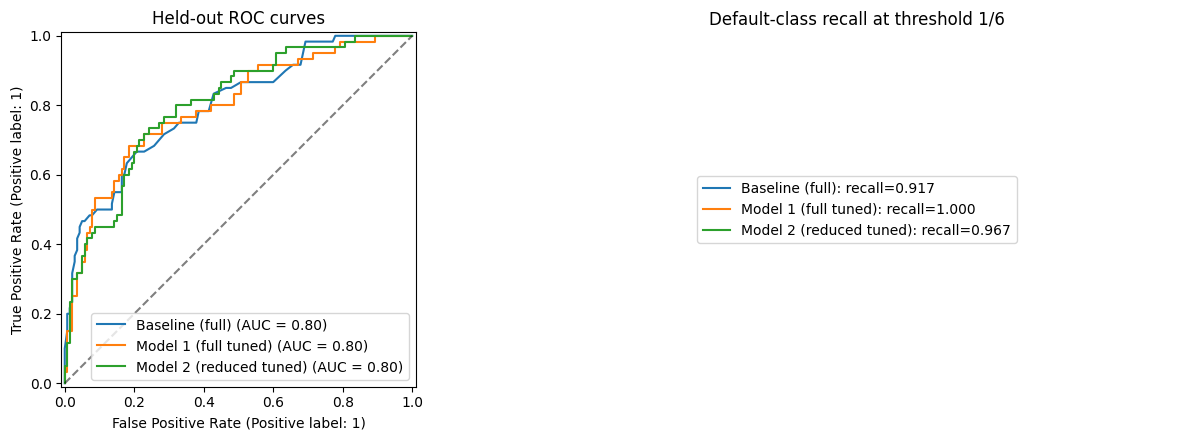

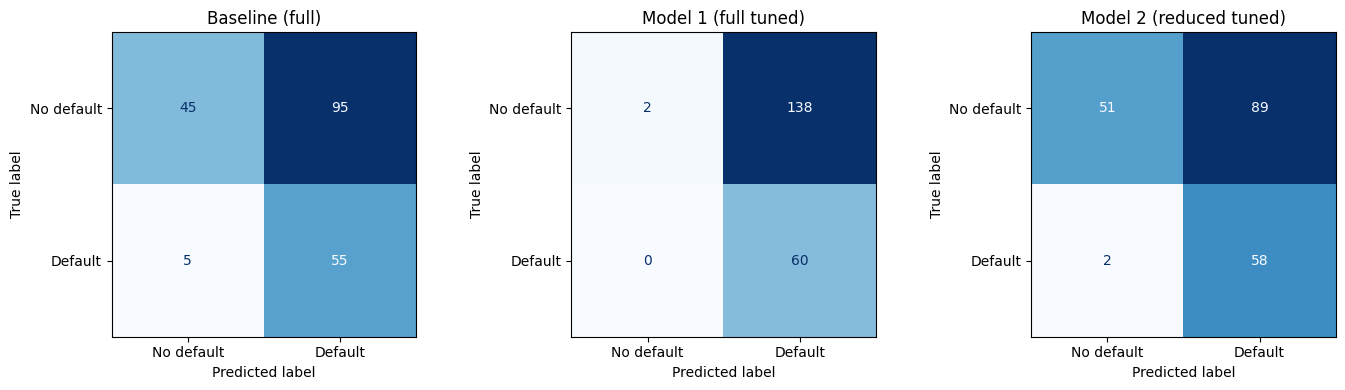

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (prob, labels) in predictions.items():
    RocCurveDisplay.from_predictions(rf_y_test, prob, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Held-out ROC curves')
for name, (prob, labels) in predictions.items():
    axes[1].plot([], [], label=f'{name}: recall={recall_score(rf_y_test, labels):.3f}')
axes[1].legend(loc='center')
axes[1].axis('off')
axes[1].set_title('Default-class recall at threshold 1/6')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (prob, labels)) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(rf_y_test, labels, labels=[0, 1],
                                            display_labels=['No default', 'Default'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Three Random Forest models were compared to assess the effects of hyperparameter tuning and feature reduction.

- **Baseline:** Achieved the highest accuracy (79.0%) but relatively low recall (48.33%), missing 31 actual defaulters.
- **Model 1 (Full Tuned):** Achieved the highest CV ROC-AUC (0.7971), recall (68.33%), and F1-score (0.6457), identifying the most defaulters but producing more false positives.
- **Model 2 (Reduced Tuned):** Achieved the highest test ROC-AUC (0.8031) using only 21 predictors, but had the lowest recall (40.0%).

**Conclusion:** Model 1 is selected for SHAP explainability because it achieved the highest cross-validation ROC-AUC and identified the most defaulters at the 0.5 threshold. Model 2 demonstrates that feature reduction can preserve discriminatory performance, although default detection was weaker at this threshold.

### Implement SHAP with Selected Model 1

In [40]:
import shap
# Select the model using training CV only, not held-out test metrics.
explain_model, explain_features = fitted[selected_by_cv]
prep = explain_model.named_steps['preprocessor']
forest = explain_model.named_steps['classifier']
X_encoded = prep.transform(rf_X_test[explain_features])
if hasattr(X_encoded, 'toarray'):
    X_encoded = X_encoded.toarray()
X_encoded = pd.DataFrame(X_encoded, columns=prep.get_feature_names_out(), index=rf_X_test.index)
explainer = shap.TreeExplainer(forest)
shap_all = explainer(X_encoded)
shap_default = shap_all[:, :, 1] if shap_all.values.ndim == 3 else shap_all
proba = predictions[selected_by_cv][0]
reconstructed = shap_default.base_values + shap_default.values.sum(axis=1)
error = np.max(np.abs(reconstructed - proba))
print('Explained model:', selected_by_cv)
print('Maximum SHAP reconstruction difference:', error)
assert error < 1e-6, 'Check the SHAP output scale/class selection.' 

Explained model: Model 1 (full tuned)
Maximum SHAP reconstruction difference: 2.3314683517128287e-15


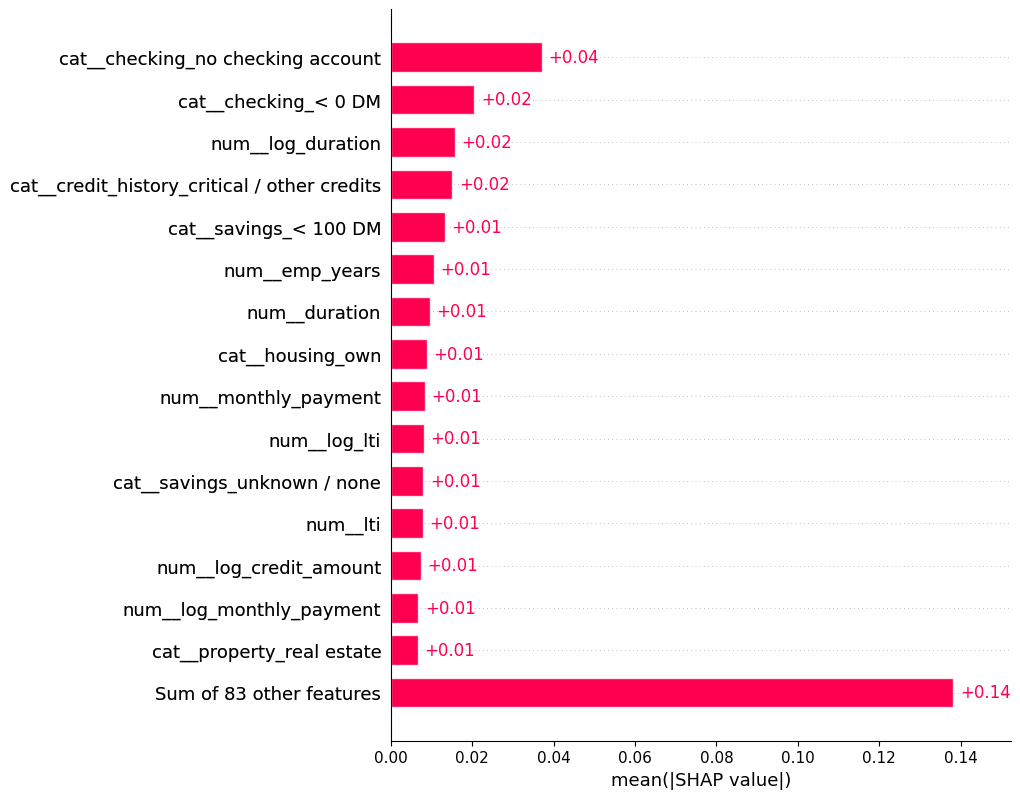

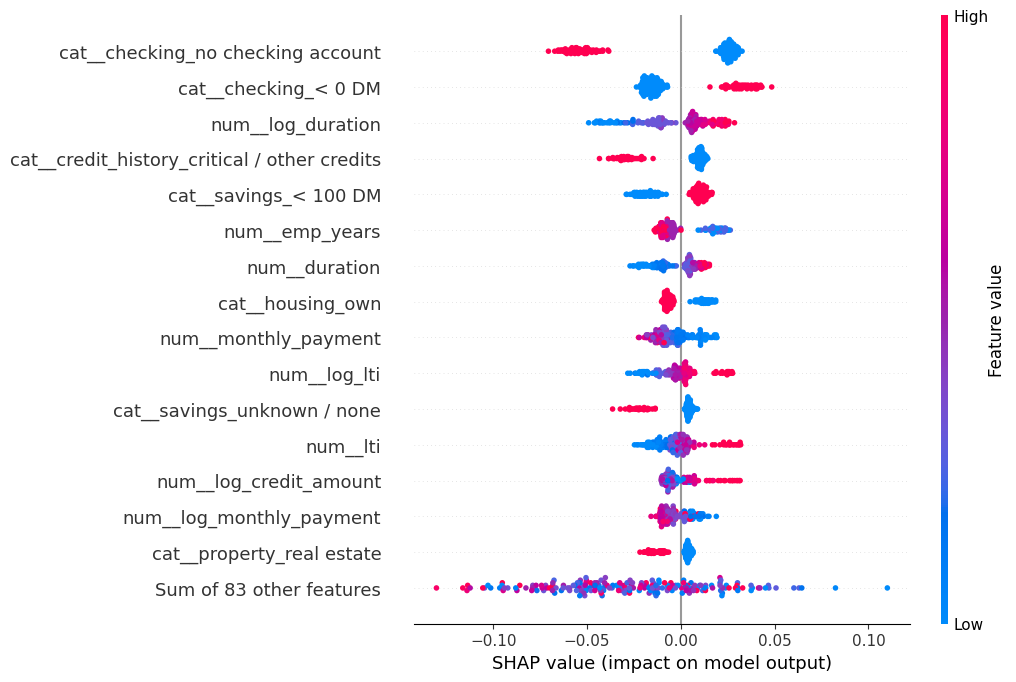

Highest predicted default risk: 3 77.92%


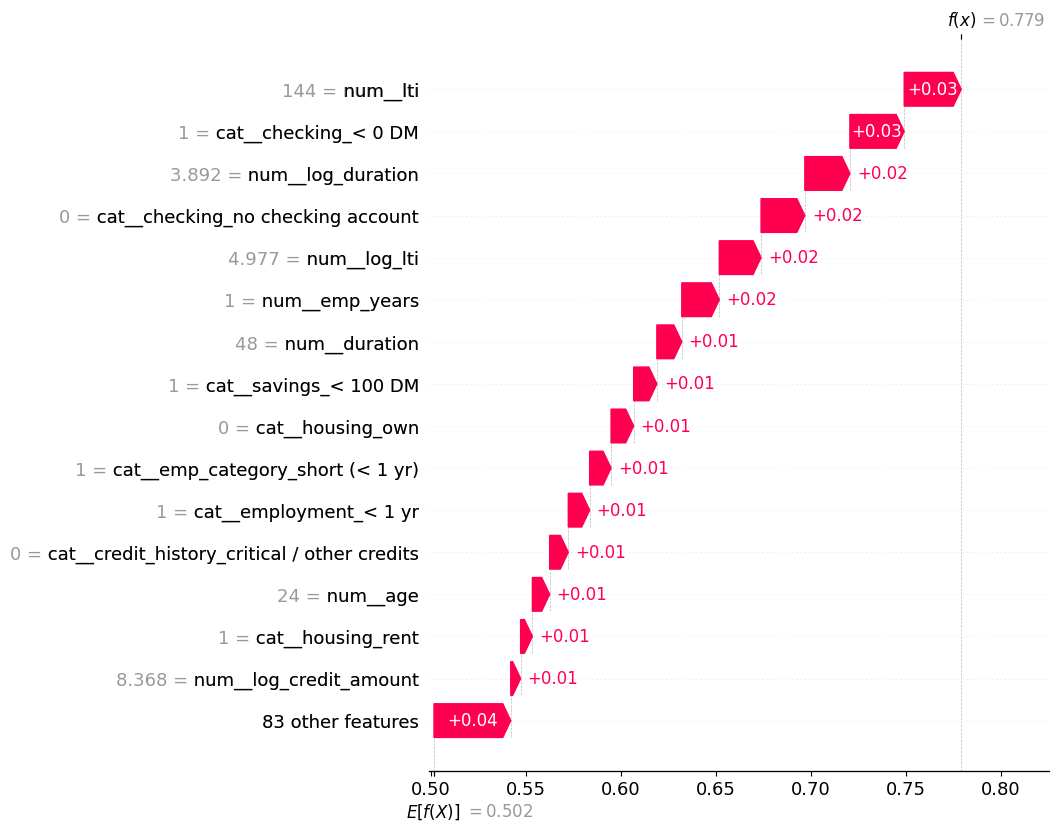

Lowest predicted default risk: 49 14.35%


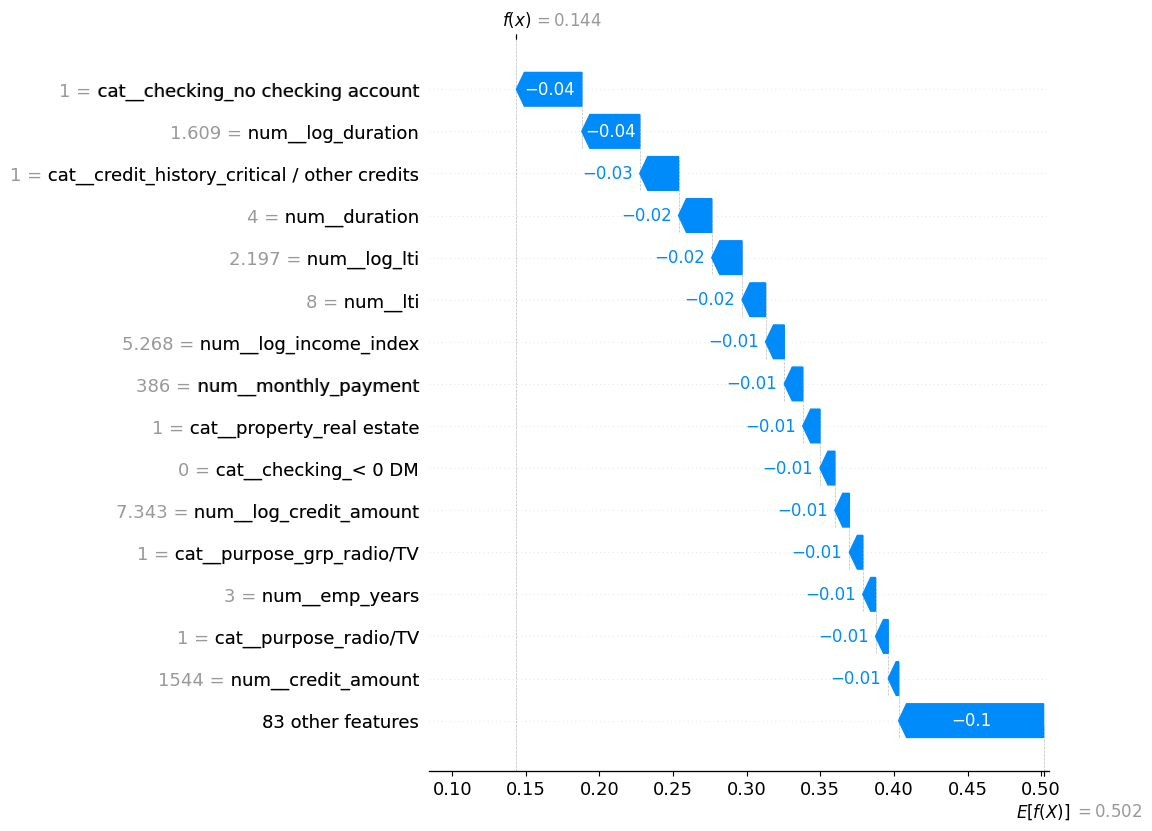

In [41]:
shap.plots.bar(shap_default, max_display=16)
shap.plots.beeswarm(shap_default, max_display=16)
hi, lo = int(np.argmax(proba)), int(np.argmin(proba))
print('Highest predicted default risk:', hi, f'{proba[hi]:.2%}')
shap.plots.waterfall(shap_default[hi], max_display=16)
print('Lowest predicted default risk:', lo, f'{proba[lo]:.2%}')
shap.plots.waterfall(shap_default[lo], max_display=16)

### D. SHAP Explainability: Interpretation

**1. Global Feature Importance (SHAP Bar Plot)**

Checking-account status is the most influential predictor, particularly having no checking account or a negative balance. Credit duration, credit history, and savings are also important. This suggests that the Random Forest relies heavily on borrowers' financial account characteristics and repayment-related information.

**2. Direction of Feature Effects (SHAP Beeswarm Plot)**

The beeswarm plot shows that negative checking balances, longer credit durations, and higher loan-to-income proxies generally increase predicted default risk. Conversely, having no checking account and shorter credit durations tend to reduce predicted risk in this model. These patterns reflect learned associations rather than causal relationships.

**3. Individual Prediction (SHAP Waterfall Plot)**

The highest-risk borrower (77.92% predicted default probability) has a high loan-to-income proxy, negative checking balance, and long credit duration (48 months), all contributing positively to default risk. Starting from the baseline predicted probability of **50.2%**, these feature contributions increase the prediction to **77.92%**.

The lowest-risk borrower has a predicted default probability of **14.35%**, demonstrating substantial variation in individual risk predictions.

**Conclusion:** SHAP improves the interpretability of the Random Forest by identifying both globally influential features and the factors driving individual borrower predictions. This supports more transparent credit risk assessment, although SHAP explanations describe model behavior rather than causation.

### Chapter 9 extension (PDP and ICE)

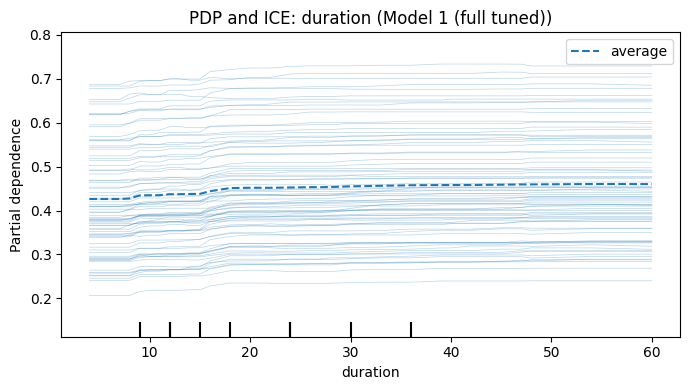

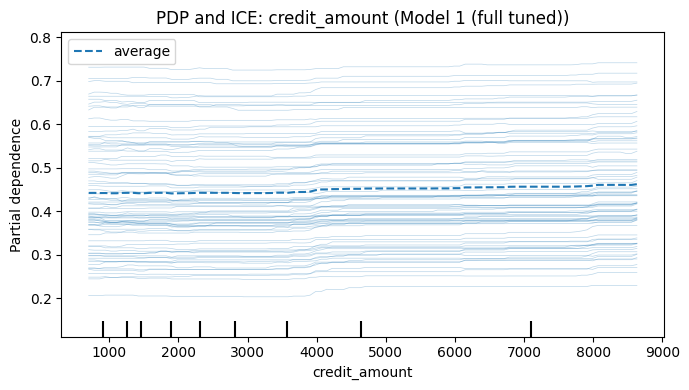

In [42]:
from sklearn.inspection import PartialDependenceDisplay
for feature in ['duration', 'credit_amount']:
    if feature in explain_features:
        fig, ax = plt.subplots(figsize=(7, 4))
        PartialDependenceDisplay.from_estimator(explain_model, rf_X_train[explain_features],
            [feature], kind='both', subsample=80, random_state=42,
            response_method='predict_proba', ax=ax)
        ax.set_title(f'PDP and ICE: {feature} ({selected_by_cv})')
        plt.tight_layout(); plt.show()

The PDPs show that predicted default risk increases slightly with **credit amount** and more noticeably with **loan duration**, before stabilizing.

The ICE curves reveal variations in predicted risk across borrowers, despite generally similar trends.

**Overall**, loan duration has a stronger average effect than credit amount. However, these plots reflect model associations, not causation, and correlated features may affect their reliability.